# Deo et al. 2024 — a model example (neural → cursor velocity)

A small, honest tutorial decoder: map the `(192, T)` threshold-crossing features to the **velocity
of the two cursors** during **open-loop** blocks. Open-loop is chosen deliberately, there the cursor
follows the *instructed* trajectory to the target, so its velocity is a clean movement label (in
closed-loop the cursor is the decoder's own output). We reuse the package extractors and the
neuralset `Segmenter`; no deo-specific ML code.

> **Data path.** Reads `NEURALSHED_DATA_ROOT` from a gitignored `./.env` at the repo root
> (`load_dotenv`). Set it there: `NEURALSHED_DATA_ROOT=/path/to/source/data`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(usecwd=True))          # NEURALSHED_DATA_ROOT from the repo-root ./.env
import numpy as np, torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

import neuralset as ns
import neuralshed.events, neuralshed.extractors      # register custom types
from neuralshed.extractors import NeuralFeatureExtractor, BehavioralSeriesExtractor
from neuralshed.datasets.deo_2024 import study
from neuralshed.datasets.utils import dataset_dir

torch.manual_seed(0)
FS, WIN_S, STRIDE_S = 50.0, 1.0, 1.0           # 50 Hz, 1 s non-overlapping windows (T=50)
root = dataset_dir("deo_2024") / "data"

# Use a handful of OPEN-LOOP timelines (blocks) for the demo, clean instructed target.
timelines = list(study.Deo2024Bimanual(path=root).iter_timelines())
OL = [i for i, t in enumerate(timelines) if t["loop_type"] == "open_loop"][:8]
events = study.Deo2024Bimanual(path=root, query=f"timeline_index in {OL}").run()
print("open-loop timelines:", events.timeline.nunique(), "| types:", events.type.value_counts().to_dict())

open-loop timelines: 8 | types: {'Stimulus': 629, 'Action': 629, 'CursorPositionSeries': 16, 'TargetPositionSeries': 16, 'SpikeCounts': 8}


## 1. Segment into windows

The `Segmenter` slides a 1 s window across each block's whole-block streams, pairing the neural
input with the cursor-position target. `input` = `SpikeCounts` (192 ch); `target` = both cursors'
`CursorPositionSeries` concatenated (`aggregation="cat"`) → `[R_x, R_y, L_x, L_y]`.

In [2]:
cache = dict(keep_in_ram=True)                  # small demo: in-process cache, no disk
segmenter = ns.dataloader.Segmenter(
    extractors={
        "input": NeuralFeatureExtractor(target_unit="Hz", event_types=("SpikeCounts",), frequency=FS, infra=cache),
        "target": BehavioralSeriesExtractor(
            event_types=("CursorPositionSeries",), frequency=FS, infra=cache, aggregation="cat"),
    },
    trigger_query="type == 'SpikeCounts'",      # anchor on the whole-block neural stream
    start=0.0, duration=WIN_S, stride=STRIDE_S,
)
ds = segmenter.apply(events); ds.prepare()
batch = ds.load_all()
X = batch.data["input"].float()                 # (N, 192, T)
pos = batch.data["target"].float()              # (N, 4, T)  cursor position [R_x, R_y, L_x, L_y]
print("neural X", tuple(X.shape), "| cursor position", tuple(pos.shape))

2026-08-14 17:37:13 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/8 [00:00<?, ?it/s]

 12%|█▎        | 1/8 [00:00<00:01,  6.58it/s]

 25%|██▌       | 2/8 [00:00<00:00,  6.90it/s]

 38%|███▊      | 3/8 [00:00<00:00,  7.05it/s]

...

  6%|▋         | 1/16 [00:03<00:54,  3.66s/it]

 44%|████▍     | 7/16 [00:03<00:03,  2.51it/s]

 81%|████████▏ | 13/16 [00:03<00:00,  5.40it/s]

100%|██████████| 16/16 [00:03<00:00,  4.06it/s]

neural X (2331, 192, 50) | cursor position (2331, 4, 50)


## 2. Position → velocity, and split

We decode **velocity** (the standard iBCI target), the time-derivative of cursor position within
each window (`au/s`). Then an 80/20 train/val split over windows.

In [3]:
Y = torch.from_numpy(np.gradient(pos.numpy(), 1.0 / FS, axis=2)).float()   # velocity (N, 4, T)
DIMS = ["R_vx", "R_vy", "L_vx", "L_vy"]         # right/left cursor velocity, x/y

N = X.shape[0]
perm = torch.randperm(N, generator=torch.Generator().manual_seed(0))
n_tr = int(0.8 * N)
tr, va = perm[:n_tr], perm[n_tr:]
Xtr, Ytr, Xva, Yva = X[tr], Y[tr], X[va], Y[va]
print("X", tuple(X.shape), "| Y(vel)", tuple(Y.shape), "| train/val:", len(tr), len(va))

X (2331, 192, 50) | Y(vel) (2331, 4, 50) | train/val: 1864 467


## 3. Normalize, model, train

Per-channel z-scoring (stats from train only), a small temporal-convolution decoder, Adam + MSE,
keep the best-validation weights.

In [4]:
x_mu, x_sd = Xtr.mean((0, 2), keepdim=True), Xtr.std((0, 2), keepdim=True) + 1e-6
y_mu, y_sd = Ytr.mean((0, 2), keepdim=True), Ytr.std((0, 2), keepdim=True) + 1e-6
nx = lambda x: (x - x_mu) / x_sd
ny = lambda y: (y - y_mu) / y_sd
Xtr_n, Ytr_n, Xva_n, Yva_n = nx(Xtr), ny(Ytr), nx(Xva), ny(Yva)


class VelocityDecoder(nn.Module):
    def __init__(self, c_in, c_out, hidden=96, k=7, p_drop=0.1):
        super().__init__()
        pad = k // 2
        self.net = nn.Sequential(
            nn.Conv1d(c_in, hidden, k, padding=pad), nn.ReLU(), nn.Dropout(p_drop),
            nn.Conv1d(hidden, hidden, k, padding=pad), nn.ReLU(), nn.Dropout(p_drop),
            nn.Conv1d(hidden, c_out, 1),
        )

    def forward(self, x):
        return self.net(x)                       # (B, c_out, T)


model = VelocityDecoder(X.shape[1], Y.shape[1])
train_loader = DataLoader(TensorDataset(Xtr_n, Ytr_n), batch_size=64, shuffle=True)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()

best_val, best_state = float("inf"), None
for epoch in range(60):
    model.train()
    for xb, yb in train_loader:
        opt.zero_grad(); loss_fn(model(xb), yb).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        vl = loss_fn(model(Xva_n), Yva_n).item()
    if vl < best_val:
        best_val, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
    if (epoch + 1) % 20 == 0:
        print(f"epoch {epoch+1:2d}  val MSE {vl:.3f}  (best {best_val:.3f})")
model.load_state_dict(best_state)
print("best val MSE:", round(best_val, 3))

epoch 20  val MSE 0.743  (best 0.734)


epoch 40  val MSE 0.742  (best 0.732)


epoch 60  val MSE 0.735  (best 0.728)
best val MSE: 0.728


## 4. Honest metrics

Correlation and R² per velocity dimension, in original units, on held-out windows. These are a
tutorial baseline, not a tuned result; the two cursors are decoded jointly and open-loop only.

In [5]:
model.eval()
with torch.no_grad():
    pred = model(Xva_n) * y_sd + y_mu            # back to original units
P = pred.permute(1, 0, 2).reshape(4, -1).numpy()
T = Yva.permute(1, 0, 2).reshape(4, -1).numpy()
for i, d in enumerate(DIMS):
    r = np.corrcoef(P[i], T[i])[0, 1]
    r2 = 1 - ((T[i] - P[i]) ** 2).sum() / ((T[i] - T[i].mean()) ** 2).sum()
    print(f"{d}:  corr {r:.3f}   R2 {r2:.3f}")

R_vx:  corr 0.743   R2 0.548
R_vy:  corr 0.703   R2 0.488
L_vx:  corr 0.465   R2 0.212
L_vy:  corr 0.470   R2 0.199


## 5. Decoded vs true (contiguous span)

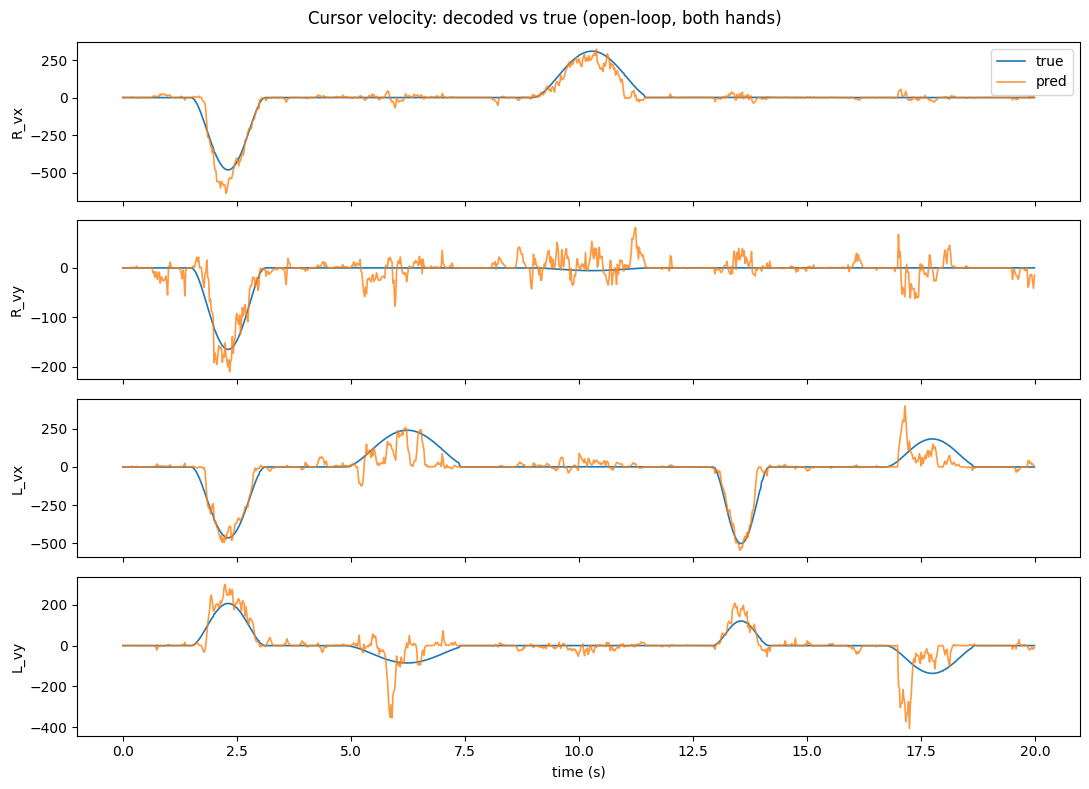

In [6]:
K = 20                                           # first 20 windows, contiguous
with torch.no_grad():
    pc = (model(nx(X[:K])) * y_sd + y_mu).permute(1, 0, 2).reshape(4, -1).numpy()
tc = Y[:K].permute(1, 0, 2).reshape(4, -1).numpy()
t = np.arange(pc.shape[1]) / FS
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for i, (ax, d) in enumerate(zip(axes, DIMS)):
    ax.plot(t, tc[i], label="true", lw=1.2)
    ax.plot(t, pc[i], label="pred", lw=1.2, alpha=0.8)
    ax.set_ylabel(d)
axes[0].legend(loc="upper right"); axes[-1].set_xlabel("time (s)")
fig.suptitle("Cursor velocity: decoded vs true (open-loop, both hands)")
plt.tight_layout(); plt.show()

## Summary

- **Reused end to end:** the `Study`, the package extractors (`NeuralFeatureExtractor`,
  `BehavioralSeriesExtractor`), and the neuralset `Segmenter`, no deo-specific ML code.
- **Task:** neural threshold crossings → both cursors' velocity, on open-loop blocks (clean
  instructed target), 1 s windows, small temporal-conv decoder.
- **Honest baseline:** metrics are a tutorial starting point, not tuned. Deferred levers that would
  lift performance: more sessions, sliding-window overlap, per-hand models, decoding *intended*
  velocity (`target − cursor`), and handling cross-session drift.
- deo is now a trainable member of the collection: the same `input`/`target` extractor pair pools
  with `singer_2025` / `fan_h1` (all `decode_target: movement`) with no code change.